# OncoSense AI — Exploratory Data Analysis

> **Educational research prototype only. Not validated for clinical use. This result is not a medical diagnosis.**

Dataset: Breast Cancer Wisconsin (Diagnostic), Wolberg, Street & Mangasarian, UCI ML Repository, CC BY 4.0, doi:10.24432/C5DW2B. Loaded via `sklearn.datasets.load_breast_cancer`.

Integrity checks use all 569 rows. **Distributional statistics use the training split only** so that the held-out test set stays unseen. All code lives in `app/ml/eda.py`; this notebook only presents it.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from app.ml import data as D
from app.ml.eda import compute_eda
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
X, y = D.load_dataset()
print(X.shape, '| malignant =', int(y.sum()), '| benign =', int((1-y).sum()))

(569, 30) | malignant = 212 | benign = 357


## 1. Dimensions, feature names and class orientation
scikit-learn encodes 0 = malignant; OncoSense re-encodes so **1 = malignant (positive class)**.

In [2]:
pd.DataFrame([s.__dict__ for s in D.feature_specs()])[['name','measurement','statistic','unit']]

,name,measurement,statistic,unit
0,mean_radius,radius,mean,image units (unspecified in source)
1,mean_texture,texture,mean,grey-scale units
2,mean_perimeter,perimeter,mean,image units (unspecified in source)
3,mean_area,area,mean,image units^2 (unspecified in source)
4,mean_smoothness,smoothness,mean,dimensionless
5,mean_compactness,compactness,mean,dimensionless
6,mean_concavity,concavity,mean,dimensionless
7,mean_concave_points,concave_points,mean,dimensionless
8,mean_symmetry,symmetry,mean,dimensionless
9,mean_fractal_dimension,fractal_dimension,mean,dimensionless


## 2. Integrity: missing values, duplicates, non-finite and zero values

In [3]:
eda = compute_eda()
i = eda['integrity']
{k: i[k] for k in ['n_rows','n_features','missing_values_total','non_finite_values','duplicate_rows','negative_values','class_counts','split']}

{'n_rows': 569,
 'n_features': 30,
 'missing_values_total': 0,
 'non_finite_values': 0,
 'duplicate_rows': 0,
 'negative_values': 0,
 'class_counts': {'malignant': 212, 'benign': 357},
 'split': {'train': 455,
  'test': 114,
  'train_malignant': 170,
  'test_malignant': 42}}

In [4]:
pd.Series(i['zero_values_by_feature'], name='rows with value 0')  # concavity = 0 occurs for smooth contours

mean_concavity          13
mean_concave_points     13
concavity_se            13
concave_points_se       13
worst_concavity         13
worst_concave_points    13
Name: rows with value 0, dtype: int64

## 3. Descriptive statistics and class-wise comparison (training split)

In [5]:
st = pd.DataFrame(eda['feature_stats']).set_index('feature')
st[['mean','std','min','50%','max','skew','iqr_outliers','benign_mean','malignant_mean','cohens_d','univariate_auc']].sort_values('univariate_auc', ascending=False).round(4)

,mean,std,min,50%,max,skew,iqr_outliers,benign_mean,malignant_mean,cohens_d,univariate_auc
feature,,,,,,,,,,,
worst_perimeter,107.8605,34.1760,50.4100,97.6500,251.2000,1.1412,12,87.2190,142.4654,2.3675,0.9736
worst_radius,16.3515,4.9010,7.9300,14.9200,36.0400,1.1157,10,13.4114,21.2806,2.3288,0.9690
worst_area,890.5692,582.3462,185.2000,683.4000,4254.0000,1.9027,21,561.8123,1441.7206,1.9559,0.9682
mean_concave_points,0.0490,0.0397,0.0000,0.0333,0.2012,1.2038,9,0.0253,0.0888,2.3061,0.9636
worst_concave_points,0.1155,0.0668,0.0000,0.1010,0.2910,0.4945,0,0.0749,0.1835,2.5353,0.9627
mean_perimeter,92.2159,24.7171,43.7900,86.1800,188.5000,1.0367,12,78.1045,115.8732,2.0998,0.9457
mean_area,659.5782,360.4187,143.5000,546.4000,2501.0000,1.7202,20,463.8568,987.6994,1.8311,0.9373
mean_radius,14.1661,3.5791,6.9810,13.3400,28.1100,0.9856,11,12.1555,17.5368,2.0336,0.9368
mean_concavity,0.0892,0.0817,0.0000,0.0594,0.4268,1.4598,17,0.0461,0.1614,1.8062,0.9327


## 4. Class distribution

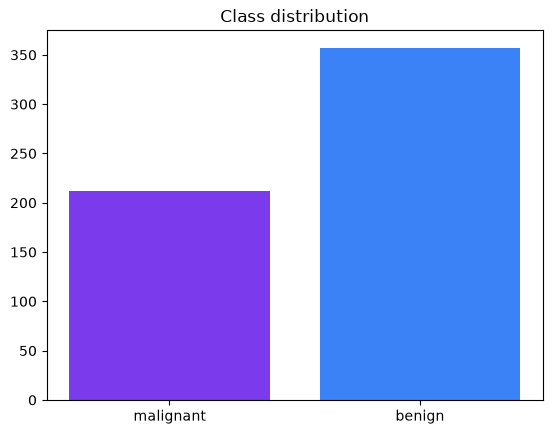

In [6]:
cc = i['class_counts']; plt.bar(cc.keys(), cc.values(), color=['#7c3aed','#3b82f6']); plt.title('Class distribution'); plt.show()

## 5. Correlation and multicollinearity

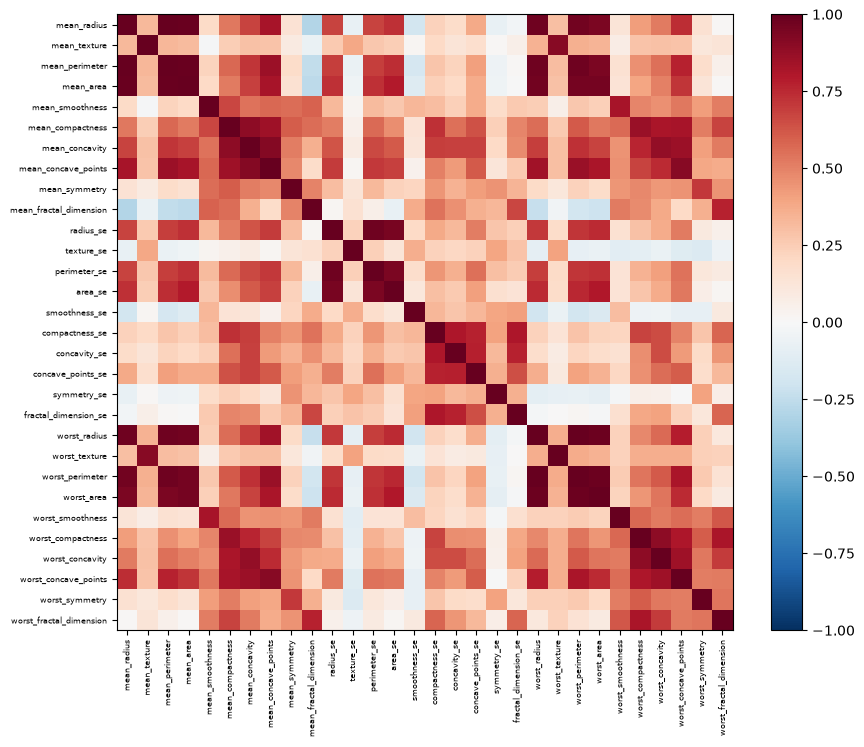

In [7]:
C = pd.DataFrame(eda['correlation']['matrix'], index=eda['correlation']['features'], columns=eda['correlation']['features'])
fig, ax = plt.subplots(figsize=(10, 8)); im = ax.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(30), C.columns, rotation=90, fontsize=6); ax.set_yticks(range(30), C.index, fontsize=6); fig.colorbar(im); plt.show()

In [8]:
pd.DataFrame(eda['high_correlation_pairs']).head(15)

,a,b,r
0,mean_radius,mean_perimeter,0.997815
1,worst_radius,worst_perimeter,0.993719
2,mean_radius,mean_area,0.986740
3,mean_perimeter,mean_area,0.985960
4,worst_radius,worst_area,0.983107
5,worst_perimeter,worst_area,0.976665
6,radius_se,perimeter_se,0.974705
7,mean_perimeter,worst_perimeter,0.970006
8,mean_perimeter,worst_radius,0.969332
9,mean_radius,worst_radius,0.969256


In [9]:
pd.DataFrame(eda['vif']).head(10).round(1)  # VIF > 10 indicates severe multicollinearity

,feature,vif
0,mean_perimeter,4110.6
1,mean_radius,4041.8
2,worst_radius,799.6
3,worst_perimeter,419.6
4,mean_area,348.2
5,worst_area,326.1
6,radius_se,80.9
7,perimeter_se,78.8
8,mean_concavity,74.9
9,mean_concave_points,70.7


## 6. Distributions and box plots (mean features)

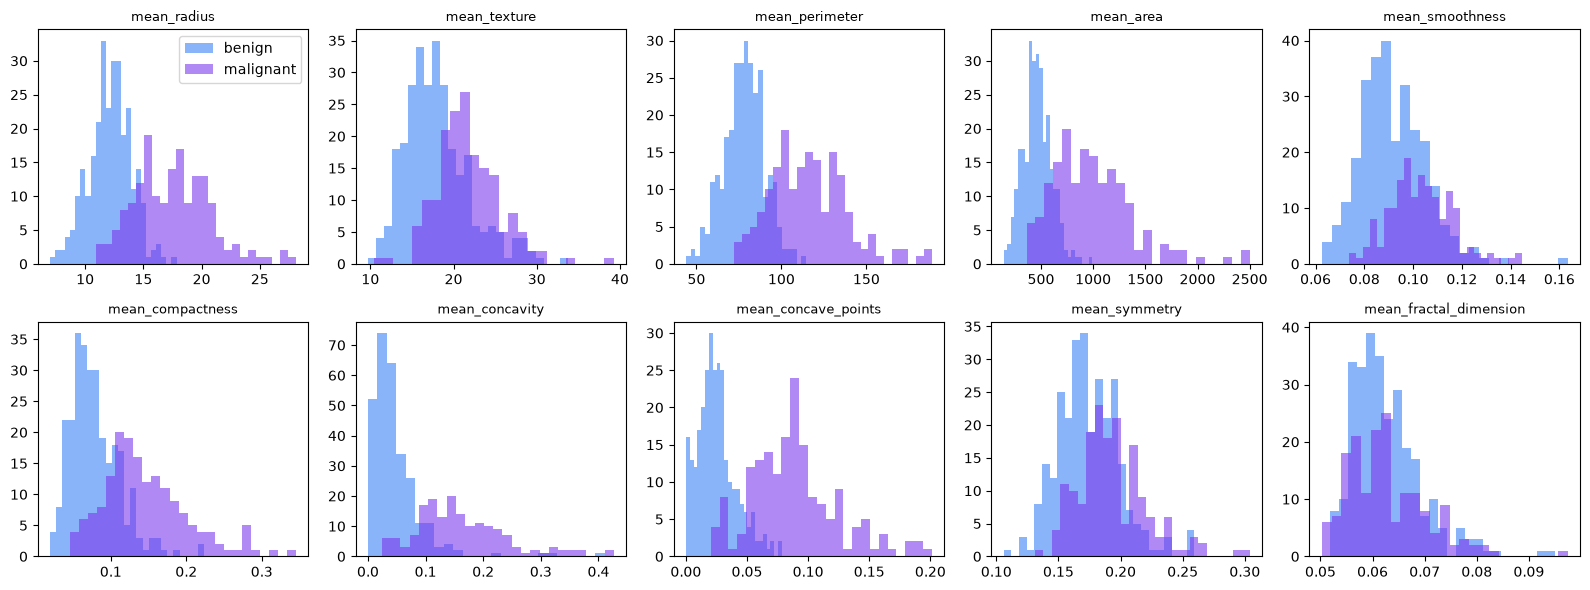

In [10]:
Xtr, Xte, ytr, yte = D.split_dataset(X, y)
feats = [f for f in D.FEATURE_NAMES if f.startswith('mean_')]
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, f in zip(axes.ravel(), feats):
    ax.hist(Xtr.loc[ytr==0, f], bins=25, alpha=.6, label='benign', color='#3b82f6')
    ax.hist(Xtr.loc[ytr==1, f], bins=25, alpha=.6, label='malignant', color='#7c3aed'); ax.set_title(f, fontsize=9)
axes[0,0].legend(); plt.tight_layout(); plt.show()

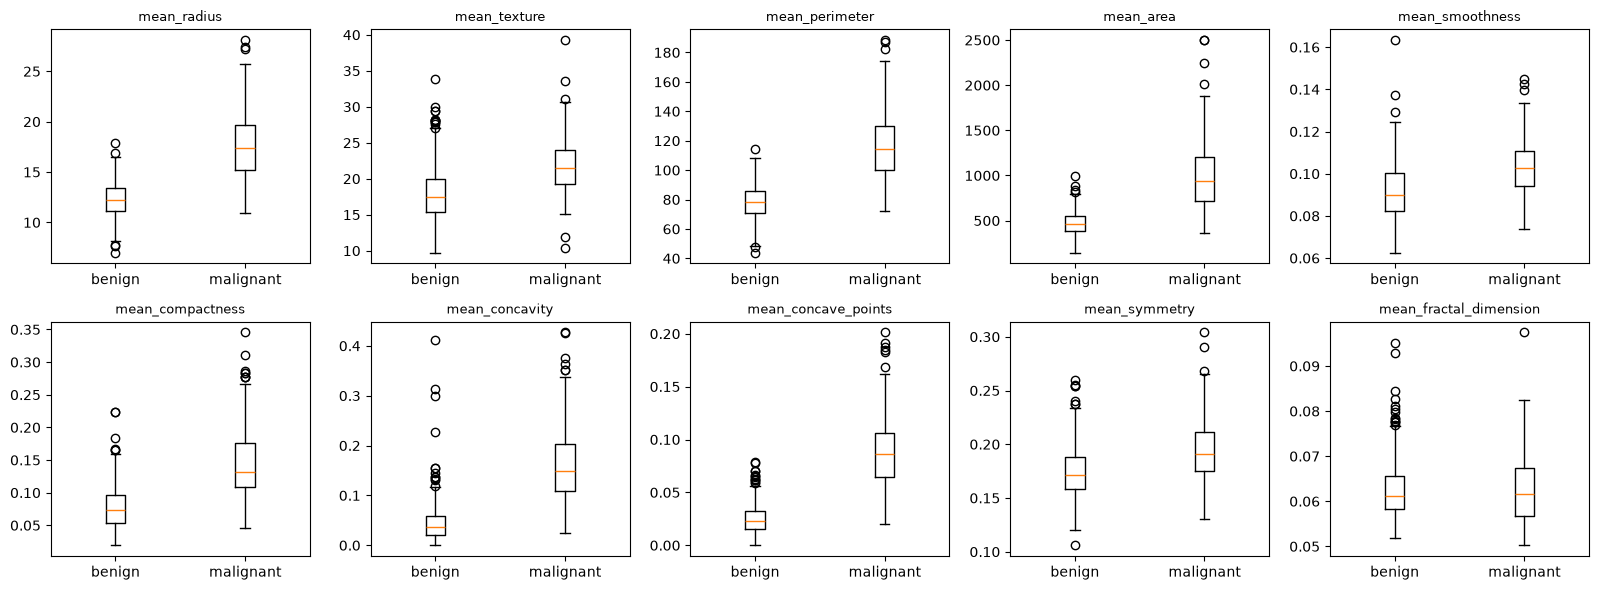

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, f in zip(axes.ravel(), feats):
    ax.boxplot([Xtr.loc[ytr==0, f], Xtr.loc[ytr==1, f]], tick_labels=['benign','malignant']); ax.set_title(f, fontsize=9)
plt.tight_layout(); plt.show()

## 7. Outliers
IQR-rule counts per feature (training split). Outliers are **kept**: they are plausible biological/measurement extremes, and removing them would bias evaluation. Scaling is learned inside pipelines.

In [12]:
st['iqr_outliers'].sort_values(ascending=False).head(10)

feature
area_se                 53
perimeter_se            34
radius_se               31
compactness_se          24
concavity_se            24
fractal_dimension_se    23
symmetry_se             22
worst_area              21
worst_symmetry          20
mean_area               20
Name: iqr_outliers, dtype: int64

## 8. Feature scaling requirement

In [13]:
print(eda['scaling']['note']); print('orders of magnitude between feature means:', round(eda['scaling']['orders_of_magnitude_between_feature_means'], 2))

Feature means span several orders of magnitude (e.g. area vs fractal dimension), so distance- and margin-based models (KNN, SVM) and regularised logistic regression need standardisation; tree models do not.
orders of magnitude between feature means: 5.37


## 9. PCA — exploratory only (not used by any model)

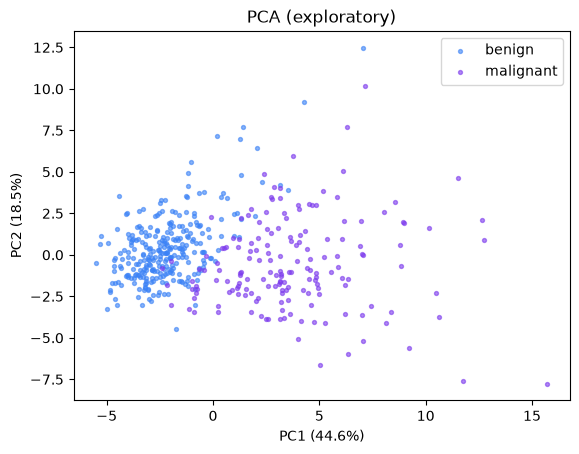

cumulative variance, first 5 PCs: [0.446 0.631 0.727 0.793 0.849]


In [14]:
P = pd.DataFrame(eda['pca']['points']); evr = eda['pca']['explained_variance_ratio']
for lab, c in [('benign','#3b82f6'), ('malignant','#7c3aed')]:
    q = P[P.label==lab]; plt.scatter(q.pc1, q.pc2, s=8, alpha=.6, c=c, label=lab)
plt.xlabel(f'PC1 ({evr[0]:.1%})'); plt.ylabel(f'PC2 ({evr[1]:.1%})'); plt.legend(); plt.title('PCA (exploratory)'); plt.show()
print('cumulative variance, first 5 PCs:', np.cumsum(evr[:5]).round(3))

## 10. Model-based feature importance
See the trained-model artifacts (`artifacts/explainability.json`), Explainable AI page, and `docs/MODEL_EVALUATION.md`. Univariate AUCs above are a model-free complement.

In [15]:
import json
exp = json.load(open('../artifacts/explainability.json'))
pd.DataFrame(exp['shap_global']).head(10).round(4)

,feature,mean_abs_shap
0,worst_texture,0.0568
1,mean_concave_points,0.0411
2,mean_concavity,0.0346
3,worst_concavity,0.0341
4,worst_radius,0.0340
5,worst_area,0.0324
6,mean_texture,0.0312
7,worst_perimeter,0.0299
8,radius_se,0.0282
9,texture_se,0.0271


## Observations
* No missing values, no duplicate rows, no negative values; zeros occur only in concavity / concave-points features.
* Moderate class imbalance (37.3% malignant) → report recall, specificity, AUC, not accuracy alone.
* Severe multicollinearity among size features (radius/perimeter/area; VIF in the thousands) → prefer regularised models; interpret attributions cautiously.
* Size, concavity and concave-point features separate the classes strongly on their own (univariate AUC > 0.9); fractal dimension, smoothness SE and texture SE barely do.
* Feature scales differ by several orders of magnitude → standardisation needed for LR/SVM/KNN (done inside pipelines).